In [1]:
import torch
import math
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from batteryml.pipeline import Pipeline
from batteryml.pipeline import build_dataset
from batteryml.builders import FEATURE_EXTRACTORS, LABEL_ANNOTATORS
from batteryml.feature.base import BaseFeatureExtractor
from batteryml.label.base import BaseLabelAnnotator
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
!rm -rf cache

In [2]:
def plot_predictions_by_battery(y_true, y_pred, cell_ids, is_soh=True, smooth_alpha=None, ncols=2):
    """
    Plot predictions against ground truth, grouping batteries in a grid (two columns by default).
    
    y_true: array or list of ground-truth labels
    y_pred: array or list of predictions
    cell_ids: battery ID for each sample
    smooth_alpha: optional (e.g., 0.05); applies EMA smoothing to each prediction series
    ncols: number of grid columns (two by default, for layouts such as 2x2 or 3x2)
    """
    # Flatten inputs in case they are lists of batches or PyTorch tensors.
    if isinstance(y_true, list):
        y_true = np.concatenate([y.flatten() if isinstance(y, np.ndarray) else y.detach().cpu().numpy().flatten() for y in y_true])
    else:
        y_true = np.array(y_true).flatten()

    if isinstance(y_pred, list):
        y_pred = np.concatenate([p.flatten() if isinstance(p, np.ndarray) else p.detach().cpu().numpy().flatten() for p in y_pred])
    else:
        y_pred = np.array(y_pred).flatten()
        
    cell_ids = np.array(cell_ids).flatten()
    
    unique_cells = np.unique(cell_ids)
    num_cells = len(unique_cells)
    
    if num_cells == 0:
        print("There are no batteries to display.")
        return

    # Calculate the required number of rows automatically.
    nrows = math.ceil(num_cells / ncols)
    
    # Create the overall figure with subplots.
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)
    axes_flat = axes.flatten()  # Flatten the axes array for sequential iteration.
    
    ylabel = 'SOH' if is_soh else 'RUL (cycles)'
    
    for i, cell_id in enumerate(unique_cells):
        ax = axes_flat[i]
        mask = (cell_ids == cell_id)
        y_true_cell = y_true[mask]
        y_pred_cell = y_pred[mask]
        
        # Ground Truth
        ax.plot(y_true_cell, label='Ground truth', color='black', linewidth=2)
        
        # Predictions
        if smooth_alpha is not None:
            ax.plot(y_pred_cell, label='Raw prediction', color='crimson', alpha=0.3, linestyle='--')
            y_pred_smoothed = pd.Series(y_pred_cell).ewm(alpha=smooth_alpha, adjust=False).mean().to_numpy()
            ax.plot(y_pred_smoothed, label=f'EMA (α={smooth_alpha})', color='red', linewidth=1.8)
        else:
            ax.plot(y_pred_cell, label='Prediction', color='crimson', linestyle='--', linewidth=1.5)
            
        ax.set_xlabel('Cycle')
        ax.set_ylabel(ylabel)
        ax.set_title(f'Battery: {cell_id}')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    # Hide unused grid slots when the number of batteries is odd (e.g., 3 batteries in a 2x2 grid).
    for j in range(num_cells, len(axes_flat)):
        axes_flat[j].set_visible(False)
        
    plt.tight_layout()
    plt.show()

# State of health (SOH)

In [3]:
import numpy as np
import torch

def create_sliding_window_dataset_cnn_soh(
    cells, 
    window_size=5, 
    fixed_length=256,  # Required fixed input length for the CNN.
    mode='relative', 
    as_percentage=False
):
    X, y, cell_ids = [], [], []
    
    for cell_idx, cell in enumerate(cells):
        cell_identifier = getattr(cell, 'cell_id', f"Cell_{cell_idx}")
        
        cycle_matrices = []
        discharge_capacities = []
        
        for cycle in cell.cycle_data:
            # Safely extract the raw arrays.
            def get_clean_array(obj, attr_name):
                val = getattr(obj, attr_name, [])
                if val is None:
                    return np.array([])
                if not isinstance(val, (list, tuple, np.ndarray)):
                    val = [val]
                clean_val = [x for x in val if x is not None]
                return np.array(clean_val, dtype=float)
            
            v = get_clean_array(cycle, 'voltage_in_V')
            c = get_clean_array(cycle, 'current_in_A')
            t = get_clean_array(cycle, 'time_in_s')
            
            # Create an empty array for this cycle with shape (3 channels, fixed_length).
            cycle_matrix = np.zeros((3, fixed_length))
            
            # INTERPOLATE: Resample the curves when enough data is available.
            if len(v) > 1 and len(c) > 1 and len(t) > 1:
                # Target normalized time axis (e.g., 256 points from 0 to 1).
                idx_new = np.linspace(0, 1, fixed_length)
                
                # Interpolate each signal based on its original length.
                v_resampled = np.interp(idx_new, np.linspace(0, 1, len(v)), v)
                c_resampled = np.interp(idx_new, np.linspace(0, 1, len(c)), c)
                t_resampled = np.interp(idx_new, np.linspace(0, 1, len(t)), t)
                
                cycle_matrix[0, :] = v_resampled
                cycle_matrix[1, :] = c_resampled
                cycle_matrix[2, :] = t_resampled
                
            cycle_matrices.append(cycle_matrix)
            
            # SOH label.
            cap = getattr(cycle, 'discharge_capacity_in_Ah', 0.0)
            if isinstance(cap, (list, np.ndarray, torch.Tensor)):
                cap = float(np.max(cap)) if len(cap) > 0 else 0.0
            else:
                cap = float(cap) if cap is not None else 0.0
            discharge_capacities.append(cap)
            
        total_cycles = len(cycle_matrices)
        if total_cycles < window_size:
            continue
            
        if mode == 'relative':
            if hasattr(cell, 'nominal_capacity_in_Ah') and cell.nominal_capacity_in_Ah:
                nominal_capacity = float(cell.nominal_capacity_in_Ah)
            else:
                nominal_capacity = discharge_capacities[0] if discharge_capacities[0] > 0 else 1.0

        # --- GENERATE WINDOWS FOR THE CNN ---
        for i in range(total_cycles - window_size + 1):
            window = cycle_matrices[i : i + window_size]
            
            # window_array initially has shape (window_size, 3_channels, fixed_length).
            window_array = np.array(window)
            
            # REORDER DIMENSIONS FOR PYTORCH.
            # PyTorch Conv2d expects (channels, height, width).
            # Convert (window, channels, length) to (channels, window, length).
            # Original indices: 0=window, 1=channels, 2=length. New order: 1, 0, 2.
            tensor_cnn = np.transpose(window_array, (1, 0, 2))
            
            X.append(tensor_cnn)
            
            # Calculate the SOH label for this window.
            current_cycle_idx = i + window_size - 1
            Qd = discharge_capacities[current_cycle_idx]
            
            if mode == 'relative':
                soh = Qd / nominal_capacity
                if as_percentage:
                    soh *= 100.0
            else:
                soh = Qd 
                
            y.append(float(soh))
            cell_ids.append(cell_identifier)
            
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), np.array(cell_ids)

In [4]:
# =====================================================================
# 1. THE WORKAROUND: Dummy classes to satisfy the pipeline.
# =====================================================================
if 'DummyFeature' not in FEATURE_EXTRACTORS.class_mapping:
    @FEATURE_EXTRACTORS.register()
    class DummyFeature(BaseFeatureExtractor):
        def process_cell(self, cell): 
            return torch.randn(1)
        # Override __call__ to prevent torch.stack errors.
        def __call__(self, cells):
            return torch.randn(len(cells), 1)

if 'DummyLabel' not in LABEL_ANNOTATORS.class_mapping:
    @LABEL_ANNOTATORS.register()
    class DummyLabel(BaseLabelAnnotator):
        def process_cell(self, cell): 
            return torch.randn(1)
        def __call__(self, cells):
            return torch.randn(len(cells))

# Load the configuration.
pipeline = Pipeline(config_path='configs/baselines/sklearn/rf/calce_rf.yaml', workspace='workspace/calce_rf')

# Temporarily override the in-memory YAML configuration to use the dummy classes.
pipeline.config['feature'] = {'name': 'DummyFeature'}
pipeline.config['label'] = {'name': 'DummyLabel'}

Missing expected config fields: ['feature', 'label', 'feature_transformation', 'label_transformation']
workspace/calce_rf


In [5]:
# =====================================================================
# 2. SAFE DATA EXTRACTION
# =====================================================================
# build_dataset should now run in milliseconds without crashing.
dataset_dummy, raw_data = build_dataset(pipeline.config, device='cpu')

train_cells = raw_data['train_cells']
test_cells = raw_data['test_cells']

Reading test data: 100%|██████████| 4/4 [00:00<00:00,  6.73it/s]


In [6]:
from sklearn.model_selection import train_test_split

train_cells_split, dev_cells_split = train_test_split(train_cells, test_size=0.20, random_state=42)

window = 5
feature_names = ['voltage_in_V', 'current_in_A', 'time_in_s']
X_train, y_train, train_cell_ids = create_sliding_window_dataset_cnn_soh(train_cells_split, window_size=window, fixed_length=64)
X_dev, y_dev, dev_cell_ids = create_sliding_window_dataset_cnn_soh(dev_cells_split, window_size=window, fixed_length=64)
X_test, y_test, test_cell_ids = create_sliding_window_dataset_cnn_soh(test_cells, window_size=window, fixed_length=64)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_dev shape: {X_dev.shape} | y_dev shape: {y_dev.shape}")
print(f"X_test shape: {X_test.shape} | y_test shape: {y_test.shape}")

X_train shape: (7323, 3, 5, 64) | y_train shape: (7323,)
X_dev shape: (1724, 3, 5, 64) | y_dev shape: (1724,)
X_test shape: (5199, 3, 5, 64) | y_test shape: (5199,)


In [7]:
# Temporarily flatten: (N, 3, 5, 256) -> (N, 3840).
n_muestras, canales, alto, ancho = X_train.shape
X_train_flat = X_train.reshape(n_muestras, -1)
X_dev_flat = X_dev.reshape(X_dev.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Scale the data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_dev_scaled = scaler.transform(X_dev_flat)
X_test_scaled = scaler.transform(X_test_flat)
import joblib
joblib.dump(scaler, 'scaler64normal.joblib')

# Restore the original 4D shape for the CNN.
X_train = X_train_scaled.reshape(n_muestras, canales, alto, ancho)
X_dev = X_dev_scaled.reshape(X_dev.shape[0], canales, alto, ancho)
X_test = X_test_scaled.reshape(X_test.shape[0], canales, alto, ancho)

## MLP (Pytorch)

In [8]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# 1. Convert to tensors, ensuring the float32 data type.
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
# X_train_tensor = X_train_tensor.transpose(2, 3)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
# X_test_tensor = X_test_tensor.transpose(2, 3)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

X_dev_tensor = torch.tensor(X_dev, dtype=torch.float32)
y_dev_tensor = torch.tensor(y_dev, dtype=torch.float32)
# 2. Create the datasets.
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
dev_dataset = TensorDataset(X_dev_tensor, y_dev_tensor)

# 3. Create the DataLoaders (set batch_size, e.g., 32 or 64).
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
dev_loader = DataLoader(dev_dataset, batch_size=batch_size, shuffle=False)

print(f"Tensor X_train shape: {X_train_tensor.shape}")
print(f"Tensor X_test shape: {X_test_tensor.shape}")
print(f"Tensor X_dev shape: {X_dev_tensor.shape}")

Tensor X_train shape: torch.Size([7323, 3, 5, 64])
Tensor X_test shape: torch.Size([5199, 3, 5, 64])
Tensor X_dev shape: torch.Size([1724, 3, 5, 64])


In [9]:
import torch
import math
from torch import nn


def train_loop(dataloader, model, loss_fn, optimizer, device):
    model.train() 
    running_loss = 0.0
    
    for batch_x, batch_y in dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        
        # Inferencia y cálculo explícito de pérdida
        preds = model(batch_x, batch_y)
        loss = loss_fn(preds.view(-1), batch_y.view(-1))
        
        # Filtro de protección antinumérico
        if torch.isinf(loss) or torch.isnan(loss):
            continue
            
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * batch_x.size(0)
        
    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_rmse = np.sqrt(epoch_loss)
    return epoch_loss, epoch_rmse


def test_loop(dataloader, model, loss_fn, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            preds = model(batch_x, batch_y)
            loss = loss_fn(preds.view(-1), batch_y.view(-1))
            
            running_loss += loss.item() * batch_x.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())
            
    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_rmse = np.sqrt(epoch_loss)
    return epoch_loss, epoch_rmse, np.array(all_preds), np.array(all_labels)

In [40]:
from batteryml.models.rul_predictors.cnn import CNNRULPredictor
from early_stopping import EarlyStopping
import time
import random
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training on: {device}")

# Instantiate the model using the exact dimensions of the 4D input array.
model = CNNRULPredictor(
    in_channels=3, 
    channels=3,          # Base number of filters; increase to 32 or 64 for more complexity.
    input_height=5,       # Window size.
    input_width=64,      # Interpolated fixed input length.
    kernel_size=(1, 5)    # Rectangular kernel to avoid excessively reducing the Y axis (height 5).
).to(device)

early_stopping = EarlyStopping(patience=80, delta=1e-4, save_path='best_cnn_64.pth')

# 0.001
learning_rate = 5e-4
weight_decay = 1e-3
torch.manual_seed(0)
random.seed(0)
np.random.seed(0)


loss_fn = nn.MSELoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=20, min_lr=1e-6
)


epochs = 200
stopping_epoch = epochs
train_losses, train_accuracies, dev_losses, dev_accuracies = [], [], [], []

start = time.time()

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss, train_rmse = train_loop(train_loader, model, loss_fn, optimizer, device)
    dev_loss, dev_rmse, _, _ = test_loop(dev_loader, model, loss_fn, device)
    
    print(f"Epoch {t+1}: Train RMSE = {train_rmse:.4f} | Dev RMSE = {dev_rmse:.4f}")
    
    # 1. Ajuste dinámico del Learning Rate según el error de validación
    scheduler.step(dev_loss)
    
    # 2. Guardado de métricas
    dev_losses.append(dev_loss)
    dev_accuracies.append(dev_rmse)
    train_losses.append(train_loss)
    train_accuracies.append(train_rmse)
    
    # 3. Evaluación de parada temprana y guardado de checkpoint
    early_stopping(dev_loss, model, t)
    
    if early_stopping.early_stop:
        print(f"\n[Early stopping] Development performance did not improve for {early_stopping.patience} epochs. Stopping training...")
        stopping_epoch = t + 1
        break

end = time.time()
print("Done!")
print(f'Training time: {end-start:.2f}s')

# 4. Restauración de los pesos del mejor modelo obtenido en validación
early_stopping.restore_best_weights(model)

Training on: cpu
Epoch 1
-------------------------------
Epoch 1: Train RMSE = 1.1682 | Dev RMSE = 1.0312
Epoch 2
-------------------------------
Epoch 2: Train RMSE = 0.6132 | Dev RMSE = 0.3473
Epoch 3
-------------------------------
Epoch 3: Train RMSE = 0.2401 | Dev RMSE = 0.3087
Epoch 4
-------------------------------
Epoch 4: Train RMSE = 0.2097 | Dev RMSE = 0.2858
Epoch 5
-------------------------------
Epoch 5: Train RMSE = 0.1927 | Dev RMSE = 0.2712
Epoch 6
-------------------------------
Epoch 6: Train RMSE = 0.1809 | Dev RMSE = 0.2567
Epoch 7
-------------------------------
Epoch 7: Train RMSE = 0.1714 | Dev RMSE = 0.2486
Epoch 8
-------------------------------
Epoch 8: Train RMSE = 0.1629 | Dev RMSE = 0.2348
Epoch 9
-------------------------------
Epoch 9: Train RMSE = 0.1550 | Dev RMSE = 0.2239
Epoch 10
-------------------------------
Epoch 10: Train RMSE = 0.1469 | Dev RMSE = 0.2111
Epoch 11
-------------------------------
Epoch 11: Train RMSE = 0.1389 | Dev RMSE = 0.1999


In [41]:
model.eval()
# Evaluate the model.
test_loss, test_rmse, test_preds, test_labels = test_loop(test_loader, model, loss_fn, device)
print(f'Test loss: {test_loss}, test RMSE: {test_rmse}')

Test loss: 0.0006577158925825901, test RMSE: 0.025645972248729235


In [42]:
torch.save(model.state_dict(), 'model_states/cnn_soh_predictor3channel64.pth')

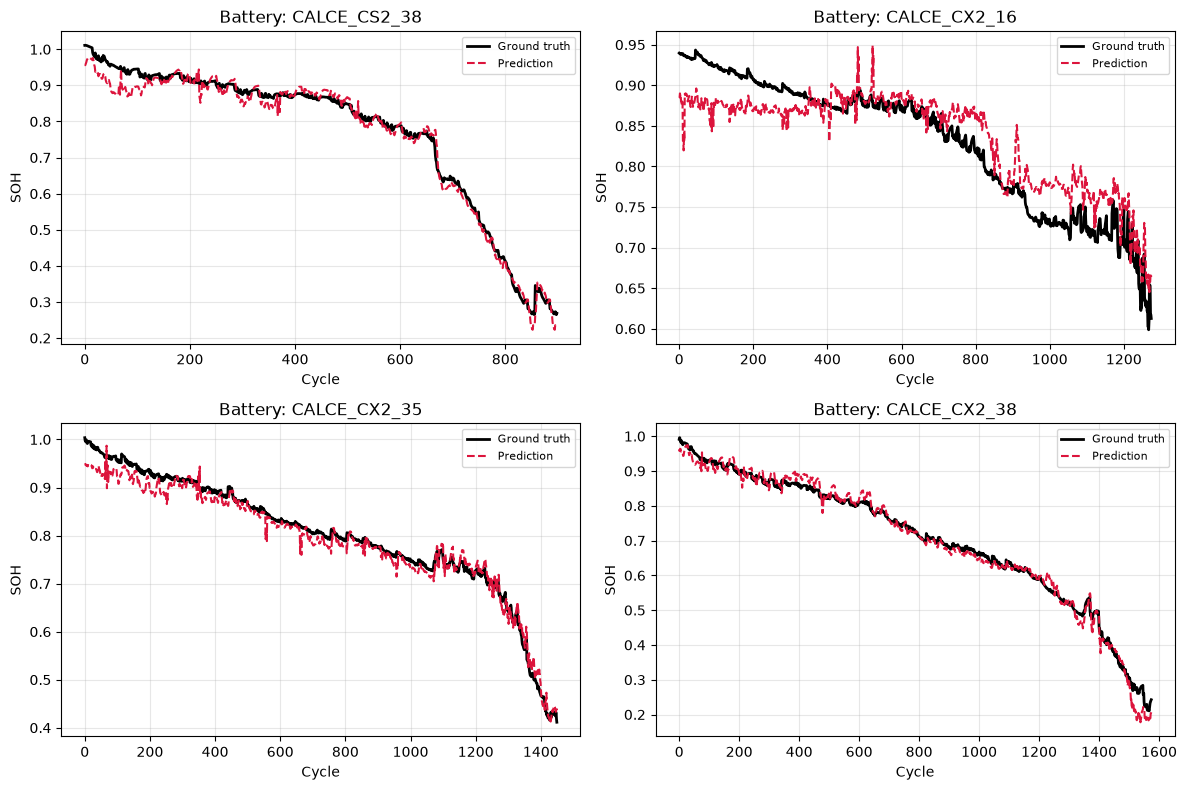

In [43]:
# plot_ground_truth_vs_predictions(predictions, y_test, is_soh=True)
predictions_flat = np.concatenate([p.flatten() for p in test_preds])
y_test_flat = np.concatenate([y.flatten() for y in test_labels])
plot_predictions_by_battery(y_test_flat, predictions_flat, cell_ids=test_cell_ids, is_soh=True)

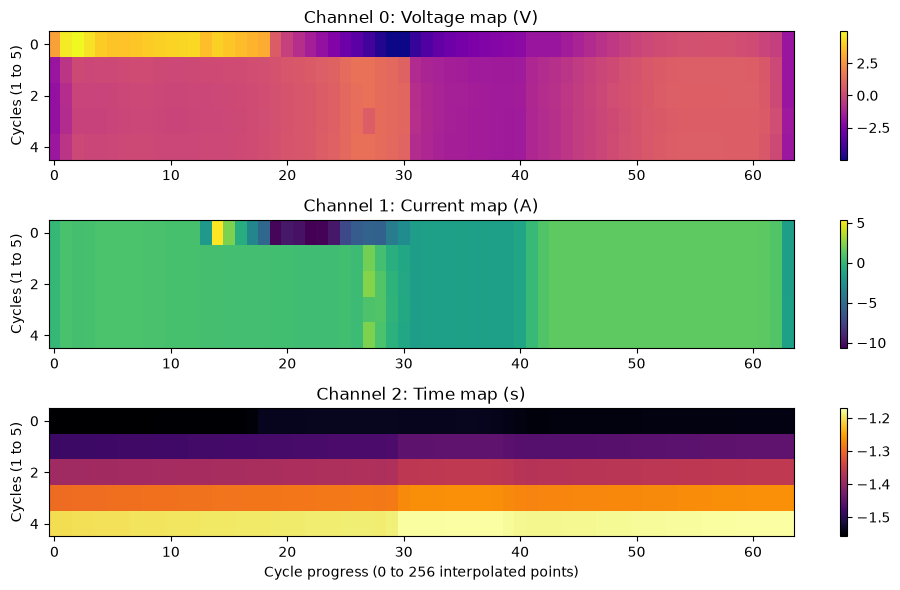

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Extract the first training sample (one window of five cycles).
# Expected shape of X_train[0]: (3_channels, 5_height, 256_width).
muestra = X_train[0] 

# Separate the three channels.
mapa_voltaje = muestra[0]
mapa_corriente = muestra[1]
mapa_tiempo = muestra[2]

fig, axes = plt.subplots(3, 1, figsize=(10, 6))

# Plot voltage.
im0 = axes[0].imshow(mapa_voltaje, aspect='auto', cmap='plasma')
axes[0].set_title('Channel 0: Voltage map (V)')
axes[0].set_ylabel('Cycles (1 to 5)')
fig.colorbar(im0, ax=axes[0])

# Plot current.
im1 = axes[1].imshow(mapa_corriente, aspect='auto', cmap='viridis')
axes[1].set_title('Channel 1: Current map (A)')
axes[1].set_ylabel('Cycles (1 to 5)')
fig.colorbar(im1, ax=axes[1])

# Plot time.
im2 = axes[2].imshow(mapa_tiempo, aspect='auto', cmap='inferno')
axes[2].set_title('Channel 2: Time map (s)')
axes[2].set_ylabel('Cycles (1 to 5)')
axes[2].set_xlabel('Cycle progress (0 to 256 interpolated points)')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()